In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

import threading
from concurrent.futures import ThreadPoolExecutor

ROOT = Path().resolve().parents[1]
sys.path.append(str(ROOT / "src"))

from forward import magcal_numba
from forward.thread_func import thread_func

### SC-TLI
L1-L2 penalty in the space domain and structural coupling in the temporal domain

$$
P(\boldsymbol{\beta}) = 
\lambda_s \left( \alpha \left\| \boldsymbol{\beta} \right\|_1 + \frac{1 - \alpha}{2} \| \boldsymbol{\beta} \|_2^2 \right)
+
\lambda_t \sum_{\mathcal{G}_j} w_{\mathcal{G}_j} \left\| \left( \boldsymbol{D} \boldsymbol{\beta} \right)_{\mathcal{G}_j} \right\|_2
$$

In [2]:
from inversion.SCTLI_with_sens_weight import ADMMGroupLasso

In [3]:
# data misfit
def misfit(f, K, beta):
    return 0.5 * np.linalg.norm(f - K.dot(beta))**2

# penalty
def pen1(beta, alpha):
    return alpha * np.linalg.norm(beta, ord = 1) + (1 - alpha) * 0.5 * np.linalg.norm(beta)**2
    
def pen2(Dbeta, sw, num_of_cells, times):
    
    pen2 = 0
    
    for k in range(num_of_cells):
        temp = 0
        
        for j in range(times-1):
            temp += Dbeta[k + j*num_of_cells]**2
            
        pen2 += sw[k] * np.sqrt(temp)
        
    return pen2

In [4]:
def calcCurvature2(x,y):
    dif_x = np.gradient(x)
    dif_y = np.gradient(y)
    dif2_x = np.gradient(dif_x)
    dif2_y = np.gradient(dif_y)
    curvature = np.abs(dif2_x * dif_y - dif_x * dif2_y) / (dif_x **2 + dif_y **2)**1.5
    return curvature

### Model domain

In [5]:
### Construction of subsurface grid: xgrd, ygrd, zgrd ###
# incx, incy, incz : grid spacing in x, y, z directions
incx = 0.1
incy = 0.1
incz = 0.1

x = np.arange(-2.4 + 0.5*incx, 2.4, incx)
y = np.arange(-2.4 + 0.5*incy, 2.4, incy)
z = np.arange(-2.4 + 0.5*incz, 0.0, incz)
            
nx = len(x)
ny = len(y)
nz = len(z)
print("nx = {}, ny = {}, nz = {}".format(nx, ny, nz))

### Construction of subsurface grid: xgrd, ygrd, zgrd ###
[yy2, zz2, xx2] = np.meshgrid(y, z, x)
            
xgrd = xx2.reshape(-1)
ygrd = yy2.reshape(-1)
zgrd = zz2.reshape(-1)

# For visualization
xfig, yfig, zfig = [], [], []

for i in range(len(xgrd)):
    j = i // (nx*ny)
    
    # Store coordinates of 8 vertices of each grid cell
    xfig.append([xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, 
                 xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx])
    yfig.append([ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy, 
                 ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy])
    zfig.append([zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, 
                 zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz])

# Convert to numpy arrays
xfig = np.array(xfig)
yfig = np.array(yfig)
zfig = np.array(zfig)

# Block size
dim = [[incx / 2., incx / 2.], [incy / 2., incy / 2.], [incz / 2., incz / 2.]]

# Near Tokyo
# Declination (degrees)
dec = -7.
# Inclination (degrees)
inc = 50.

nx = 48, ny = 48, nz = 24


### Aeromagnetic layout (regular grids)

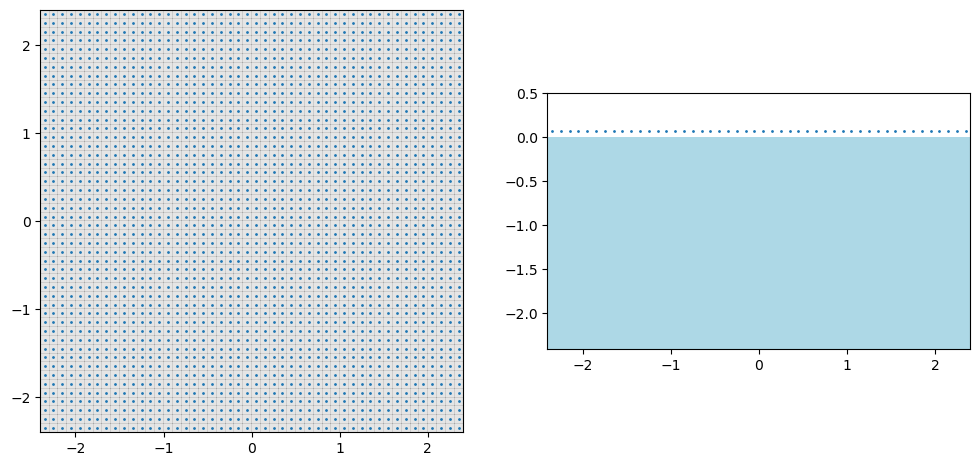

In [6]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs1, yobs1] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs1 = xobs1.reshape(-1)
yobs1 = yobs1.reshape(-1)
zobs1 = 0.07 *np.ones(len(xobs1))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs1, yobs1, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs1[(0<yobs1)&(yobs1<incy)], zobs1[(0<yobs1)&(yobs1<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

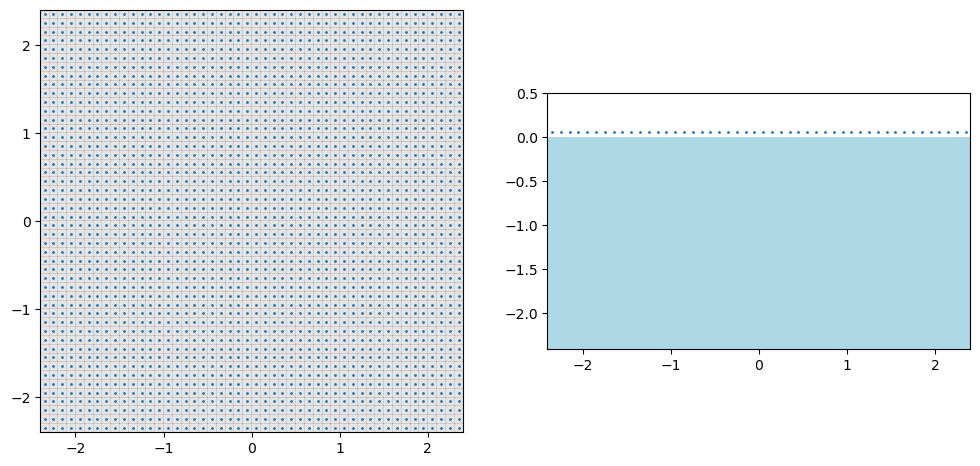

In [7]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs2, yobs2] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs2 = xobs2.reshape(-1)
yobs2 = yobs2.reshape(-1)
zobs2 = 0.06 *np.ones(len(xobs2))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs2, yobs2, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs2[(0<yobs2)&(yobs2<incy)], zobs2[(0<yobs2)&(yobs2<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

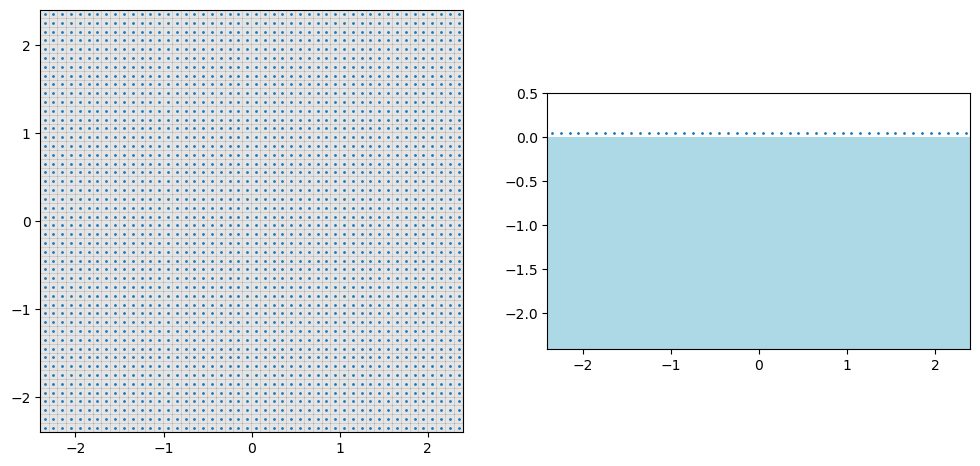

In [8]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs3, yobs3] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs3 = xobs3.reshape(-1)
yobs3 = yobs3.reshape(-1)
zobs3 = 0.05 *np.ones(len(xobs3))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs3, yobs3, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs3[(0<yobs3)&(yobs3<incy)], zobs3[(0<yobs3)&(yobs3<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

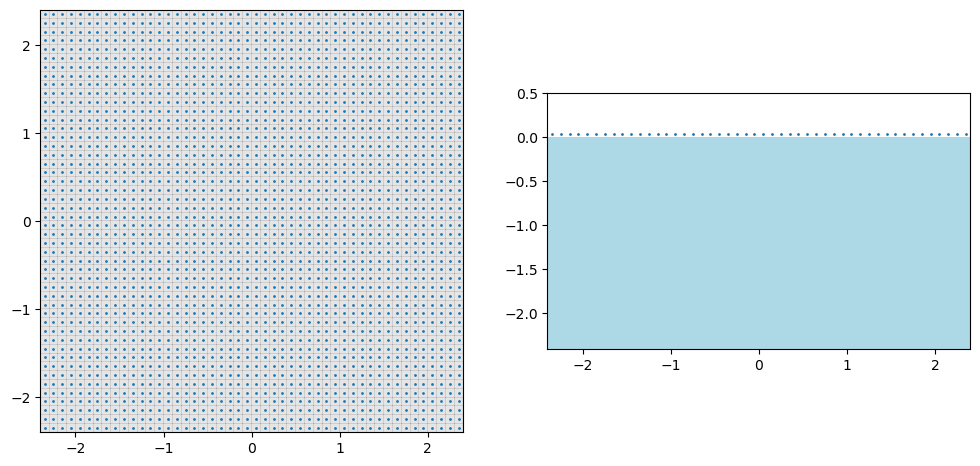

In [9]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs4, yobs4] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs4 = xobs4.reshape(-1)
yobs4 = yobs4.reshape(-1)
zobs4 = 0.04 *np.ones(len(xobs4))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs4, yobs4, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs4[(0<yobs4)&(yobs4<incy)], zobs4[(0<yobs4)&(yobs4<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

### Kernel matrix

In [10]:
from numba import njit, prange

@njit(parallel=True, fastmath=True)
def kernel_matrix2(
    exf,
    mgz,
    xobs,
    yobs,
    zobs,
    xgrd,
    ygrd,
    zgrd,
    dim,
    L
):

    nobs  = xobs.shape[0]
    ncell = xgrd.shape[0]

    xmin = np.min(xgrd)
    xmax = np.max(xgrd)

    ymin = np.min(ygrd)
    ymax = np.max(ygrd)

    K = np.zeros((nobs, ncell))

    for s in prange(ncell):

        dx1 = dim[0,0]
        dx2 = dim[0,1]

        dy1 = dim[1,0]
        dy2 = dim[1,1]

        dz1 = dim[2,0]
        dz2 = dim[2,1]

        if abs(xgrd[s] - xmin) < 1e-10:
            dx1 += L
        elif abs(xgrd[s] - xmax) < 1e-10:
            dx2 += L

        if abs(ygrd[s] - ymin) < 1e-10:
            dy1 += L
        elif abs(ygrd[s] - ymax) < 1e-10:
            dy2 += L

        dim_new = np.empty((3,2))

        dim_new[0,0] = dx1
        dim_new[0,1] = dx2

        dim_new[1,0] = dy1
        dim_new[1,1] = dy2

        dim_new[2,0] = dz1
        dim_new[2,1] = dz2

        h = magcal_numba.prism(
            mgz,
            xobs,
            yobs,
            zobs,
            xgrd[s],
            ygrd[s],
            zgrd[s],
            dim_new
        )

        K[:,s] = magcal_numba.total_force(exf, h)

        if s%1000 == 0: 
            print(s) 

    return K

In [11]:
%%time
# num of threads
from numba import set_num_threads, get_num_threads
set_num_threads(12)
print(get_num_threads())

# Unit vector creation
mgz = magcal_numba.di2xyz(dec = dec, inc = inc)
exf = mgz.copy()

# Kernel matrix
K1 = kernel_matrix2(
     exf,
     mgz,
     xobs1.astype(np.float64),
     yobs1.astype(np.float64),
     zobs1.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

K2 = kernel_matrix2(
     exf,
     mgz,
     xobs2.astype(np.float64),
     yobs2.astype(np.float64),
     zobs2.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

K3 = kernel_matrix2(
     exf,
     mgz,
     xobs3.astype(np.float64),
     yobs3.astype(np.float64),
     zobs3.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

K4 = kernel_matrix2(
     exf,
     mgz,
     xobs4.astype(np.float64),
     yobs4.astype(np.float64),
     zobs4.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

12
0
37000
14000
51000
28000
5000
42000
19000
33000
10000
47000
24000
1000
38000
15000
29000
52000
6000
43000
20000
34000
11000
48000
25000
2000
39000
16000
30000
53000
7000
44000
21000
35000
12000
49000
26000
3000
40000
17000
31000
54000
8000
45000
22000
36000
13000
50000
27000
4000
41000
18000
32000
55000
9000
23000
46000
0
37000
14000
51000
28000
5000
19000
42000
33000
10000
47000
24000
1000
38000
15000
52000
29000
6000
20000
43000
34000
11000
48000
25000
2000
39000
16000
53000
30000
7000
21000
44000
35000
12000
49000
26000
3000
40000
17000
54000
31000
8000
22000
45000
36000
13000
50000
27000
4000
41000
18000
55000
32000
9000
23000
46000
0
37000
14000
51000
28000
5000
42000
19000
33000
10000
24000
47000
1000
38000
15000
52000
29000
6000
43000
20000
34000
11000
25000
48000
2000
39000
16000
53000
30000
7000
44000
21000
35000
12000
26000
49000
3000
17000
40000
54000
31000
8000
22000
45000
36000
13000
50000
27000
4000
41000
18000
55000
32000
9000
23000
46000
0
37000
14000
51000
28000
50

In [12]:
# Depth weighting
w1 = np.linalg.norm(K1, axis=0)
X1 = K1 / w1

w2 = np.linalg.norm(K2, axis=0)
X2 = K2 / w2

w3 = np.linalg.norm(K3, axis=0)
X3 = K3 / w3

w4 = np.linalg.norm(K4, axis=0)
X4 = K4 / w4

### Input models

In [13]:
### Magnetization structure  ###

# ------------------------------------------------------------ #

# Time 1
beta1 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (0.3 < ygrd[k]) & (ygrd[k] < 1.1) & (-1.2 < zgrd[k]) & (zgrd[k] < -0.4):
                beta1[k] = -4

            # 南
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.1 < ygrd[k]) & (ygrd[k] < -0.3) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta1[k] = 4

# Time 2
beta2 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (0.3 < ygrd[k]) & (ygrd[k] < 1.1) & (-1.2 < zgrd[k]) & (zgrd[k] < -0.4):
                beta2[k] = -1.5

            # 南
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.1 < ygrd[k]) & (ygrd[k] < -0.3) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta2[k] = 4


# Time 3
beta3 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (0.3 < ygrd[k]) & (ygrd[k] < 1.1) & (-1.2 < zgrd[k]) & (zgrd[k] < -0.4):
                beta3[k] = -0.5

            # 南
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.1 < ygrd[k]) & (ygrd[k] < -0.3) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta3[k] = 4
                
# Time 4
beta4 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 北
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (0.3 < ygrd[k]) & (ygrd[k] < 1.1) & (-1.2 < zgrd[k]) & (zgrd[k] < -0.4):
                beta4[k] = 0.0

            # 南
            if (-0.4 < xgrd[k]) & (xgrd[k] < 0.4) & (-1.1 < ygrd[k]) & (ygrd[k] < -0.3) & (-1.4 < zgrd[k]) & (zgrd[k] < -0.6):
                beta4[k] = 4
                
bb1 = beta1.reshape(nz, ny, nx)
bb2 = beta2.reshape(nz, ny, nx)
bb3 = beta3.reshape(nz, ny, nx)
bb4 = beta4.reshape(nz, ny, nx)

# ------------------------------------------------------------ #

# Magnetic anomaly calculation
f1_row = K1.dot(beta1)
f2_row = K2.dot(beta2)
f3_row = K3.dot(beta3)
f4_row = K4.dot(beta4)

# Centering
f1_row = f1_row - f1_row.mean()
f2_row = f2_row - f2_row.mean()
f3_row = f3_row - f3_row.mean()
f4_row = f4_row - f4_row.mean()

# Add Gaussian noise
np.random.seed(42)
noise1 = np.random.normal(loc=0, scale=5.0, size=len(f1_row))  # 5 nT
noise2 = np.random.normal(loc=0, scale=5.0, size=len(f2_row))  # 5 nT
noise3 = np.random.normal(loc=0, scale=5.0, size=len(f3_row))  # 5 nT
noise4 = np.random.normal(loc=0, scale=5.0, size=len(f4_row))  # 5 nT

fobs1 = f1_row + noise1
fobs2 = f2_row + noise2
fobs3 = f3_row + noise3
fobs4 = f4_row + noise4

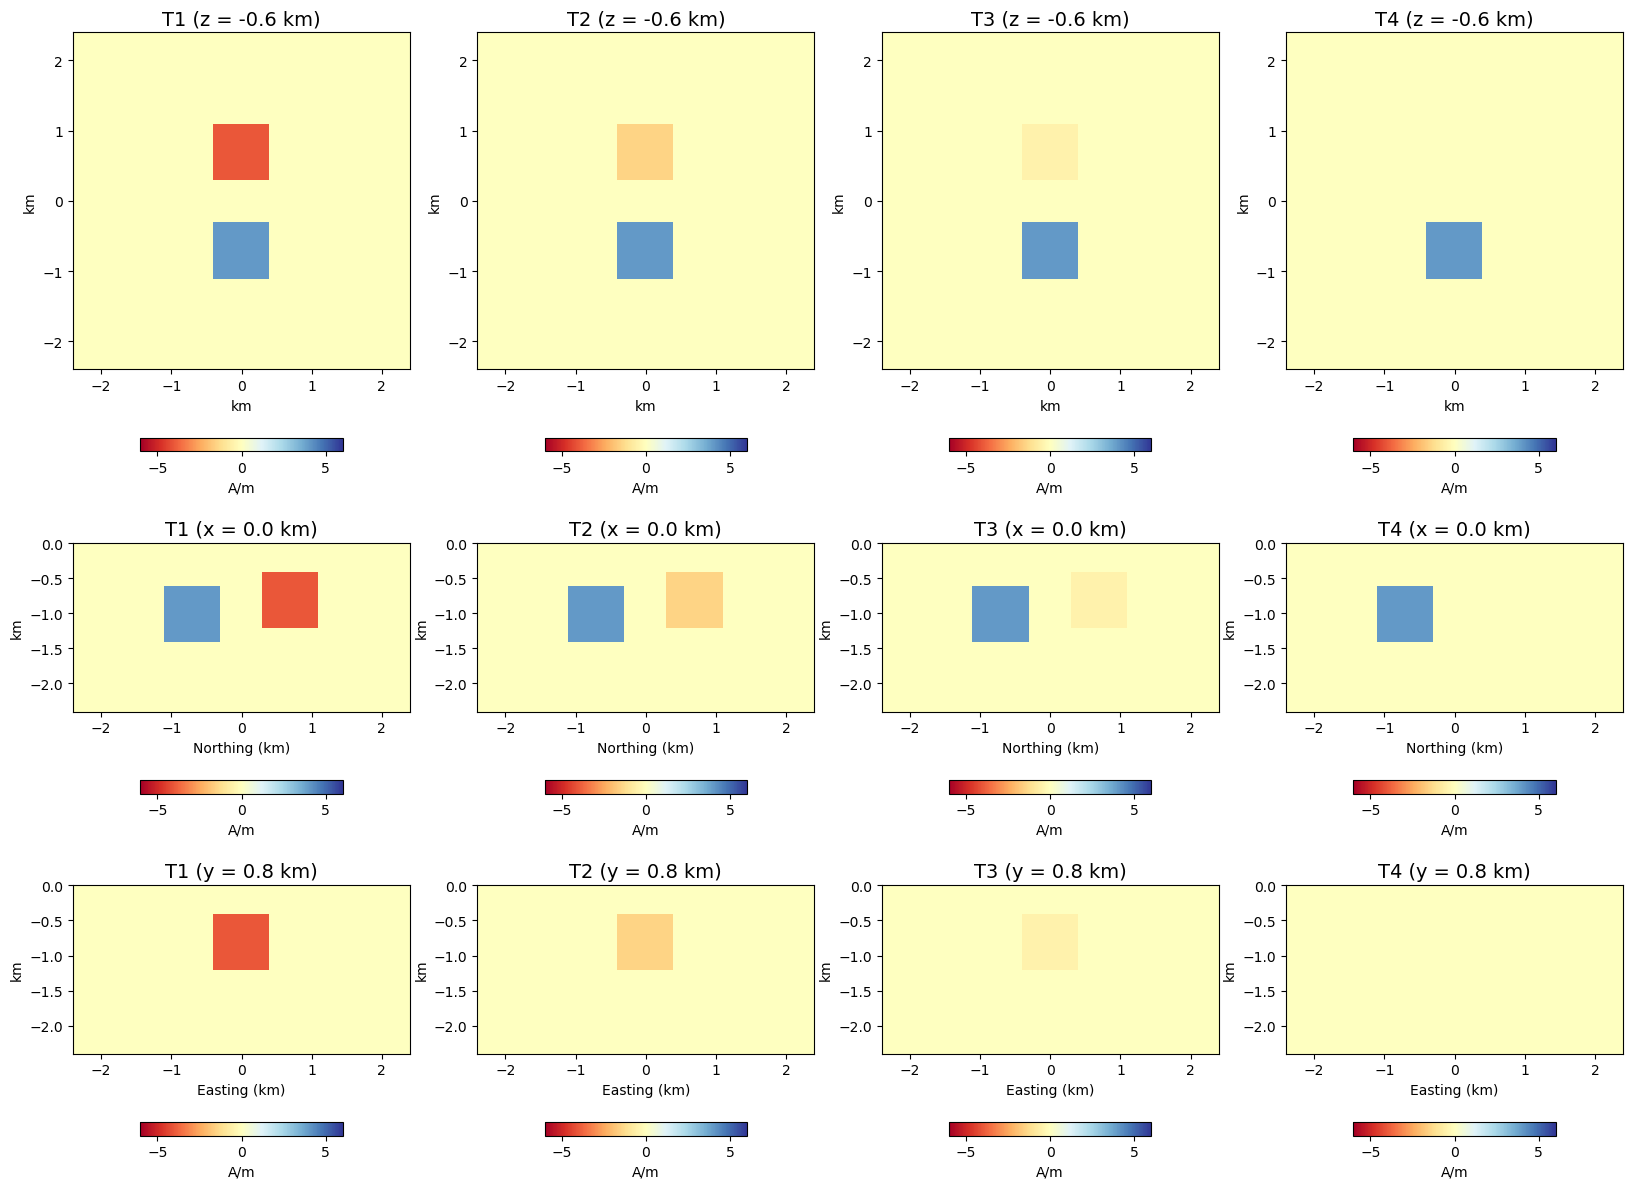

In [14]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.8
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb1[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb3[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(344)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb4[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb1[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb3[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(348)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb4[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb1[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb3[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)


ax = fig.add_subplot(3,4,12)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb4[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

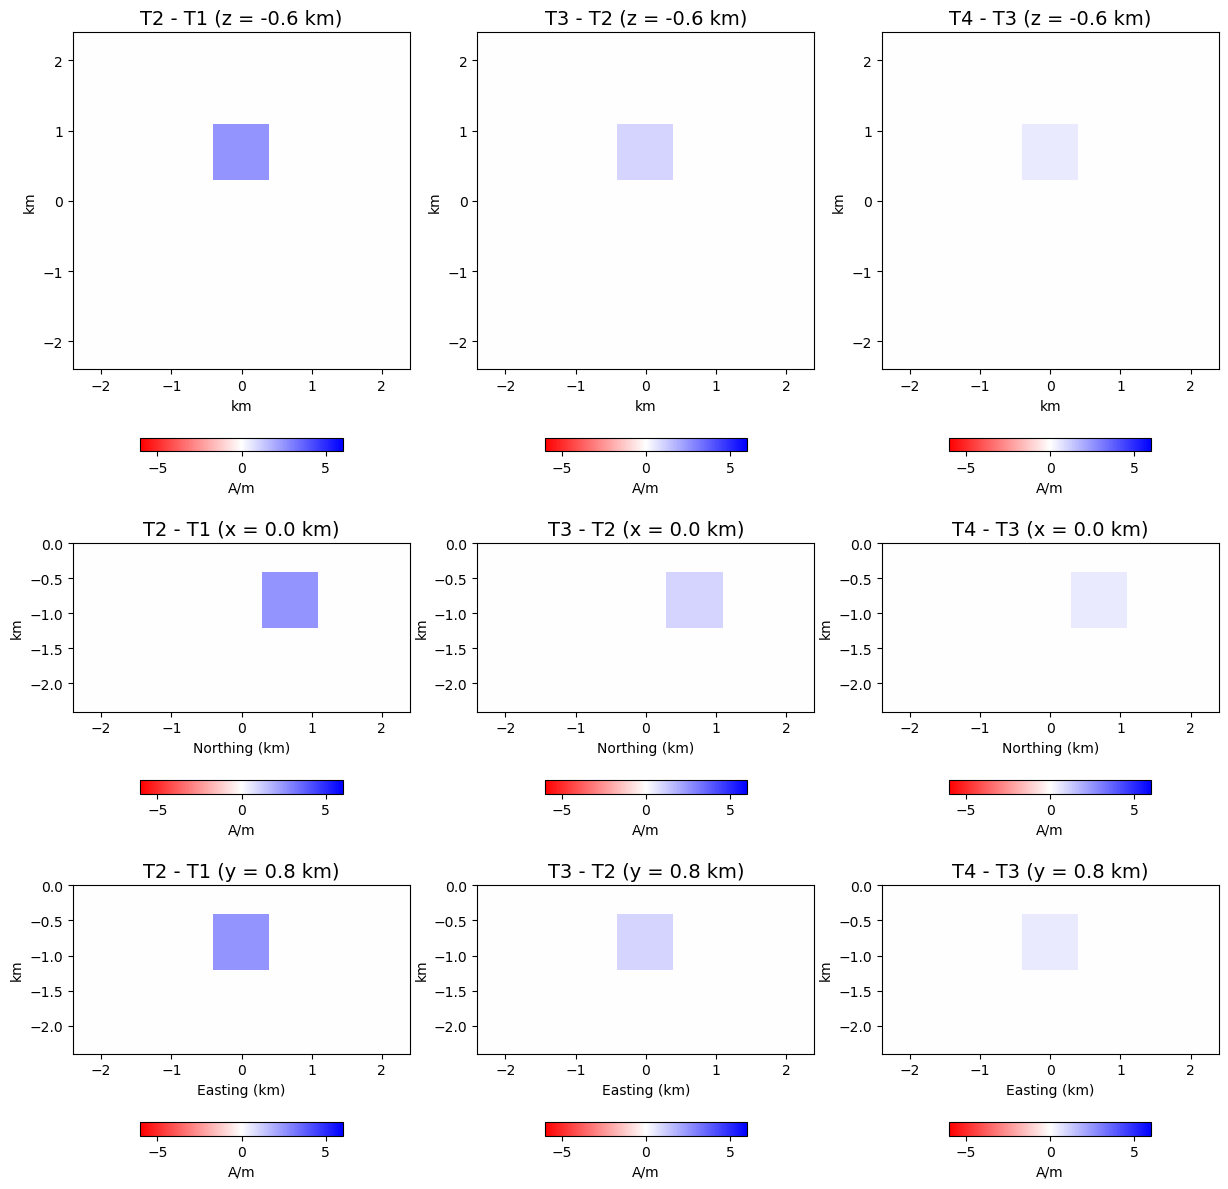

In [15]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.8
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb2 - bb1)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb3 - bb2)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb4 - bb3)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)


ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb2 - bb1)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb3 - bb2)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb4 - bb3)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb2 - bb1)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb3 - bb2)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb4 - bb3)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

### Joint Inversion

In [16]:
# Z
Z = np.r_[np.c_[X1, np.zeros(X1.shape), np.zeros(X1.shape), np.zeros(X1.shape)], 
          np.c_[np.zeros(X2.shape), X2, np.zeros(X2.shape), np.zeros(X2.shape)], 
          np.c_[np.zeros(X3.shape), np.zeros(X3.shape), X3, np.zeros(X3.shape)], 
          np.c_[np.zeros(X4.shape), np.zeros(X4.shape), np.zeros(X4.shape), X4]]

# f
fobs = np.r_[fobs1, fobs2, fobs3, fobs4]

# D
zeros = sp.sparse.diags(np.zeros(len(xgrd)))
D = sp.sparse.vstack([ sp.sparse.hstack([-sp.sparse.diags(1 / w1), sp.sparse.diags(1 / w2), zeros, zeros]), 
                       sp.sparse.hstack([zeros, -sp.sparse.diags(1 / w2), sp.sparse.diags(1 / w3), zeros]),
                       sp.sparse.hstack([zeros, zeros, -sp.sparse.diags(1 / w3), sp.sparse.diags(1 / w4)]),
                     ])

# Sensitivity parameter
sw = np.power(w1 * w2 * w3 * w4, 1/4)

print(Z.shape, fobs.shape, D.shape, sw.shape)

(9216, 221184) (9216,) (165888, 221184) (55296,)


In [17]:
%%time
# parameter
rho = 1.0
eta = 1.0

# inverse matrix
inv1 = sp.sparse.linalg.inv(rho * sp.sparse.eye(Z.shape[1]) + eta * D.T @ D)
inv2 = np.linalg.inv(np.eye(Z.shape[0]) + Z @ (inv1 @ Z.T))

C:\Users\ri710\anaconda3\envs\inv_test\lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:394: SparseEfficiencyWarning: splu converted its input to CSC format
  warn('splu converted its input to CSC format', SparseEfficiencyWarning)
C:\Users\ri710\anaconda3\envs\inv_test\lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:285: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  warn('spsolve is more efficient when sparse b '


CPU times: total: 1h 29min 43s
Wall time: 1h 10min 9s


### Step1

In [18]:
# hyper-parameters
lams_s = np.power(10., np.arange(0.5, 2.6, 0.25))
print("lams_s = {}".format(lams_s))

lam_t = 1.0  # fixed

lams_s = [  3.16227766   5.62341325  10.          17.7827941   31.6227766
  56.23413252 100.         177.827941   316.22776602]


In [19]:
# L1-L2 ratio
alpha = 0.9

In [20]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []
betas4_all = []

for lis in range(len(lams_s)):

    params_all.append([lams_s[lis], lam_t])
    print("lm1 = {}, lm2 = {}".format(lams_s[lis], lam_t))

    model = ADMMGroupLasso(lambda_s = lams_s[lis], 
                           lambda_t = lam_t, 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3)
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 4, 
              num_of_cells = nx*ny*nz
             )
    
    beta_sim1 = model.beta_[0*nx*ny*nz:1*nx*ny*nz] / w1
    beta_sim2 = model.beta_[1*nx*ny*nz:2*nx*ny*nz] / w2
    beta_sim3 = model.beta_[2*nx*ny*nz:3*nx*ny*nz] / w3
    beta_sim4 = model.beta_[3*nx*ny*nz:4*nx*ny*nz] / w4

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)
    betas4_all.append(beta_sim4)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)
betas4_all = np.array(betas4_all)

lm1 = 3.1622776601683795, lm2 = 1.0
iter = 0, delta_s = 0.5543154612736042, delta_t = 0.1037562811650544, delta = 0.5543154612736042
iter = 1000, delta_s = 0.0001647347415149072, delta_t = 0.004164736632090054, delta = 0.004164736632090054
iter = 2000, delta_s = 5.183343851522228e-05, delta_t = 0.0025454099192084027, delta = 0.0025454099192084027
iter = 3000, delta_s = 2.8867473792875565e-05, delta_t = 0.001573279047598288, delta = 0.001573279047598288
iter = 4000, delta_s = 1.8703883862077674e-05, delta_t = 0.0010490962885618246, delta = 0.0010490962885618246
Converged at iteration 4152
lm1 = 5.623413251903491, lm2 = 1.0
iter = 0, delta_s = 0.5983733712154586, delta_t = 0.1037562811650544, delta = 0.5983733712154586
iter = 1000, delta_s = 0.0004088308418462578, delta_t = 0.0024644226985962073, delta = 0.0024644226985962073
iter = 2000, delta_s = 9.078363059841869e-05, delta_t = 0.00182983704229089, delta = 0.00182983704229089
iter = 3000, delta_s = 3.585434362534316e-05, delta_t = 0.0

In [21]:
import pickle
with open('1007_Params_model_E_new_4d-1.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1007_Betas1_model_E_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1007_Betas2_model_E_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1007_Betas3_model_E_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)
with open('1007_Betas4_model_E_new_4d-1.pickle', 'wb') as f:
    pickle.dump(betas4_all, f)

In [22]:
# L-curve
rss2_1 = []
nrm2_1 = []

for lis in range(len(lams_s)):
    
    betas_temp = np.r_[betas1_all[lis]*w1, betas2_all[lis]*w2, betas3_all[lis]*w3, betas4_all[lis]*w4]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen1(betas_temp, alpha = alpha)
    
    rss2_1.append(rss_temp)
    nrm2_1.append(pen_temp)

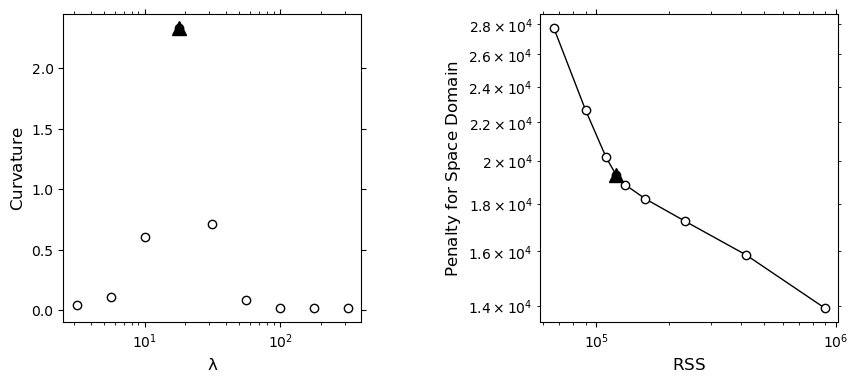

In [23]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_s, calcCurvature2(np.log(rss2_1), np.log(nrm2_1)), "o", ms=6, color='#000000',markerfacecolor='#ffffff', linewidth = 1)

num_opt_1 = np.argmax(calcCurvature2(np.log(rss2_1), np.log(nrm2_1)))

ax.semilogx(lams_s[num_opt_1], calcCurvature2(np.log(rss2_1), np.log(nrm2_1))[num_opt_1], '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
ax.ticklabel_format(style="sci",  axis="y", scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.5, 6.5)

ax = fig.add_subplot(122)
ax.loglog(rss2_1, nrm2_1, 'o-', ms=6, color='#000000', markerfacecolor='#ffffff', linewidth = 1)
ax.loglog(rss2_1[num_opt_1], nrm2_1[num_opt_1], '^', ms=10, color = "black")
ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Space Domain}$', fontsize = 12)
#ax.set_xlim(1e3, 13e4)
#ax.set_ylim(2e3, 3e4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

plt.subplots_adjust(wspace=0.6)

In [24]:
print("optimal lambda_s = {:.2f}".format(lams_s[num_opt_1]))

optimal lambda_s = 17.78


### Step.2

In [25]:
# hyper-parameters
lams_t = np.power(10., np.arange(0.0, 2.1, 0.25))
print("lams_t = {}".format(lams_t))

lams_t = [  1.           1.77827941   3.16227766   5.62341325  10.
  17.7827941   31.6227766   56.23413252 100.        ]


In [26]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []
betas4_all = []

for lit in range(len(lams_t)):

    params_all.append([lams_s[num_opt_1], lams_t[lit]])
    print("lm1 = {:.3f}, lm2 = {:.3f}".format(lams_s[num_opt_1], lams_t[lit]))

    model = ADMMGroupLasso(lambda_s = lams_s[num_opt_1], 
                           lambda_t = lams_t[lit], 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3
                          )
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 4, 
              num_of_cells = nx*ny*nz
             )
    
    beta_sim1 = model.beta_[0*nx*ny*nz:1*nx*ny*nz] / w1
    beta_sim2 = model.beta_[1*nx*ny*nz:2*nx*ny*nz] / w2
    beta_sim3 = model.beta_[2*nx*ny*nz:3*nx*ny*nz] / w3
    beta_sim4 = model.beta_[3*nx*ny*nz:4*nx*ny*nz] / w4

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)
    betas4_all.append(beta_sim4)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)
betas4_all = np.array(betas4_all)

lm1 = 17.783, lm2 = 1.000
iter = 0, delta_s = 0.6075074892673731, delta_t = 0.1037562811650544, delta = 0.6075074892673731
iter = 1000, delta_s = 0.0015798275873086538, delta_t = 0.0004308819539531233, delta = 0.0015798275873086538
Converged at iteration 1427
lm1 = 17.783, lm2 = 1.778
iter = 0, delta_s = 0.6075074892673731, delta_t = 0.12066378835716486, delta = 0.6075074892673731
iter = 1000, delta_s = 0.0015425477565617182, delta_t = 0.0005445992073219978, delta = 0.0015425477565617182
Converged at iteration 1396
lm1 = 17.783, lm2 = 3.162
iter = 0, delta_s = 0.6075074892673731, delta_t = 0.12231027006474432, delta = 0.6075074892673731
iter = 1000, delta_s = 0.001495383929701817, delta_t = 0.0007158167176116718, delta = 0.001495383929701817
Converged at iteration 1366
lm1 = 17.783, lm2 = 5.623
iter = 0, delta_s = 0.6075074892673731, delta_t = 0.12231027006474432, delta = 0.6075074892673731
iter = 1000, delta_s = 0.0014184927600030515, delta_t = 0.0010499776224808532, delta = 0.0014184

In [27]:
import pickle
with open('1007_Params_model_E_new_4d-2.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1007_Betas1_model_E_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1007_Betas2_model_E_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1007_Betas3_model_E_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)
with open('1007_Betas4_model_E_new_4d-2.pickle', 'wb') as f:
    pickle.dump(betas4_all, f)

In [28]:
# L-curve
rss2_2 = []
nrm2_2 = []

for lit in range(len(lams_t)):
    
    betas_temp = np.r_[betas1_all[lit]*w1, betas2_all[lit]*w2, betas3_all[lit]*w3, betas4_all[lit]*w4]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen2(D @ betas_temp, sw, nx*ny*nz, 4)
    
    rss2_2.append(rss_temp)
    nrm2_2.append(pen_temp)
    print(rss_temp, pen_temp)

121049.7662675424 3860.5853456386594
121236.84266465556 3722.2389356494086
121508.49535752377 3576.94547667447
121847.87485623242 3451.3832853348263
122433.12177790374 3337.5848145135888
123583.90365242749 3236.4976516230736
126078.46019594185 3133.148593902074
131554.4163794534 3014.9372425310253
142007.5579000266 2876.5741804377803


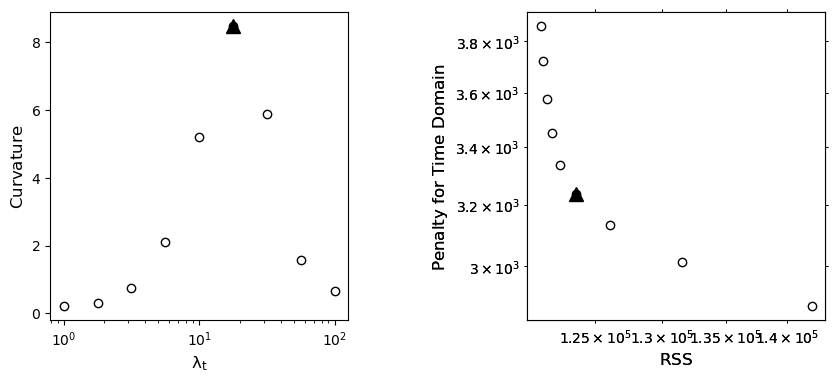

In [29]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_t, calcCurvature2(np.log(rss2_2), np.log(nrm2_2)), 
            "o", ms=6, color='k',markerfacecolor='#ffffff', linewidth = 1)

num_opt_2 = np.argmax(calcCurvature2(np.log(rss2_2), np.log(nrm2_2)))

ax.semilogx(lams_t[num_opt_2], 
            calcCurvature2(np.log(rss2_2), np.log(nrm2_2))[num_opt_2], 
            '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda_t}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

#ax.xaxis.set_ticks_position('both')
#ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
#ax.ticklabel_format(style="sci",  axis="y",scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.1, 0.65)

ax = fig.add_subplot(122)
ax.loglog(rss2_2, nrm2_2, 'o', ms=6, color='k', markerfacecolor='#ffffff', linewidth = 1)

ax.loglog(rss2_2[num_opt_2], 
          nrm2_2[num_opt_2], 
          '^', ms=10, color = "black")

ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Time Domain}$', fontsize = 12)
#ax.set_xlim(3.16e4, 3.23e4)
#ax.set_ylim(6e1, 5e2)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.6)
#ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
#ax.ticklabel_format(style="sci",  axis="y",scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.1, 0.65)

ax = fig.add_subplot(122)
ax.loglog(rss2_2, nrm2_2, 'o', ms=6, color='k', markerfacecolor='#ffffff', linewidth = 1)

ax.loglog(rss2_2[num_opt_2], 
          nrm2_2[num_opt_2], 
          '^', ms=10, color = "black")

ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Time Domain}$', fontsize = 12)
#ax.set_xlim(3.16e4, 3.23e4)
#ax.set_ylim(6e1, 5e2)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_aspect("equal")

plt.subplots_adjust(wspace=0.6)

In [30]:
print("optimal lambda_t = {}".format(lams_t[num_opt_2]))

optimal lambda_t = 17.78279410038923


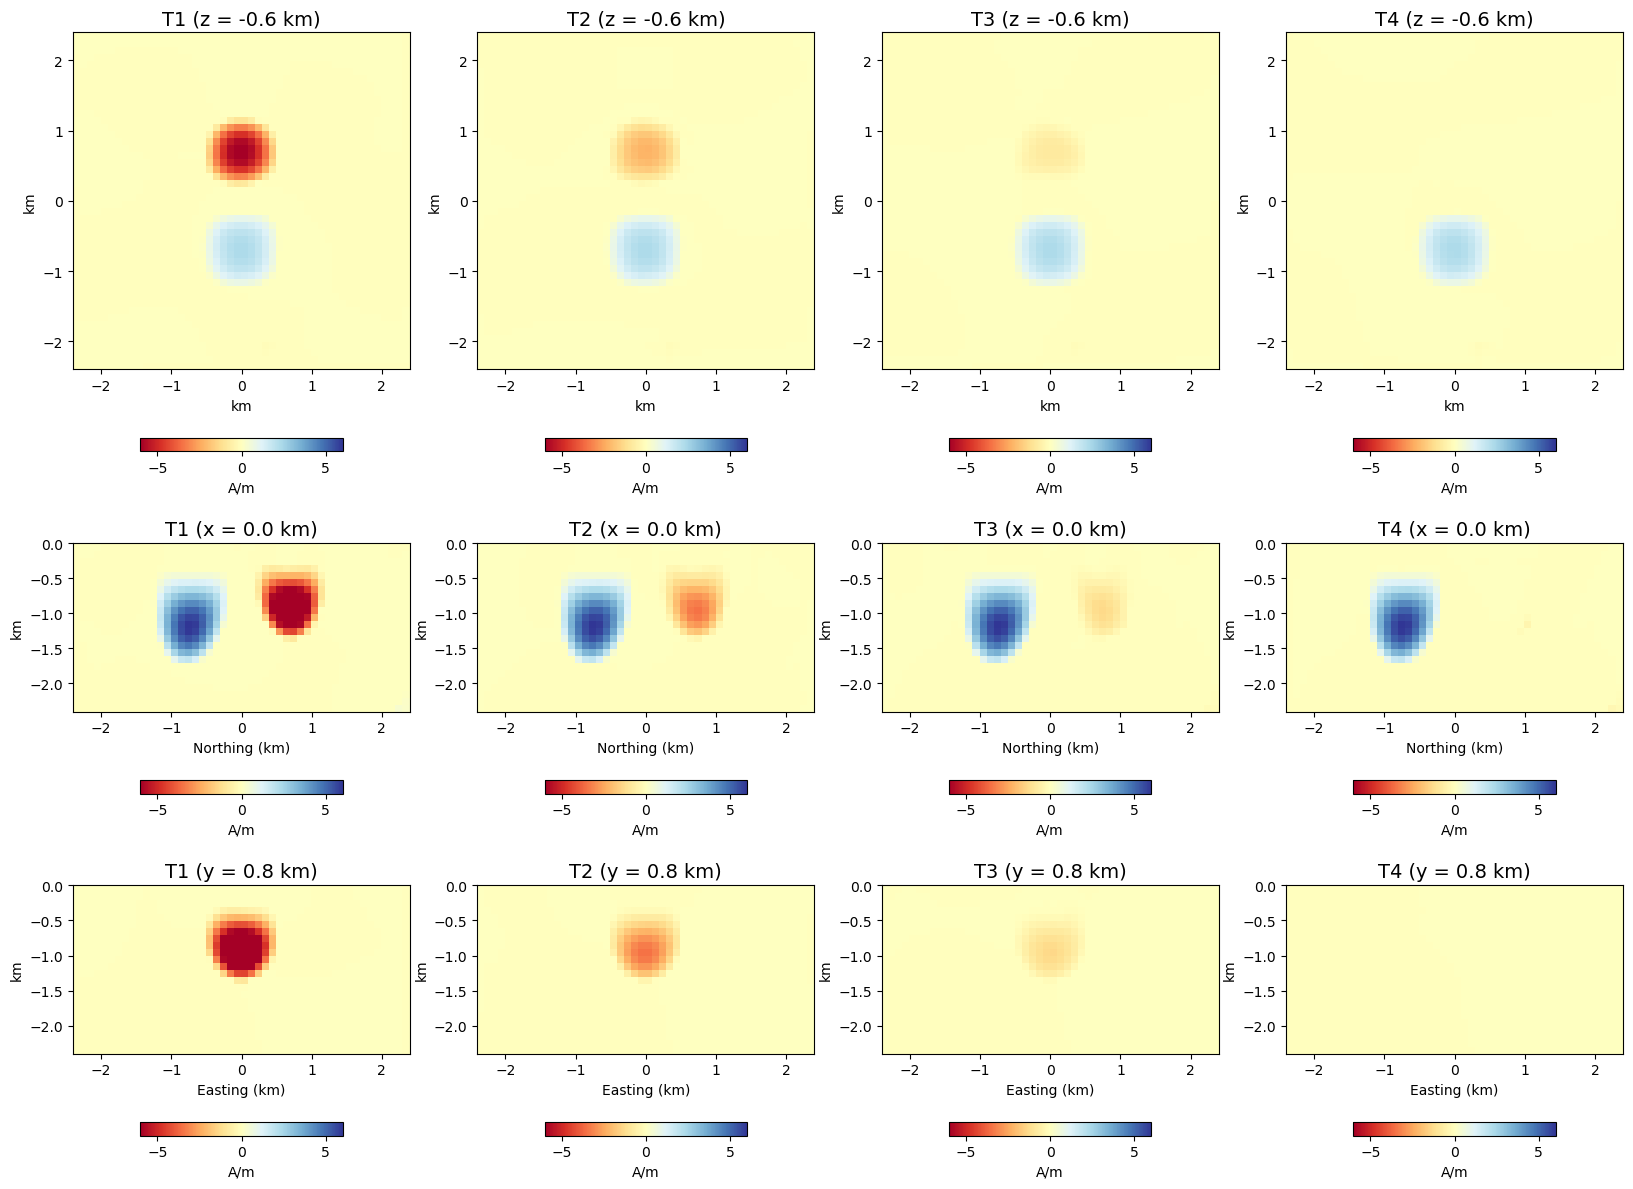

In [31]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.8
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(344)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas4_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(348)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas4_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)


ax = fig.add_subplot(3,4,12)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas4_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

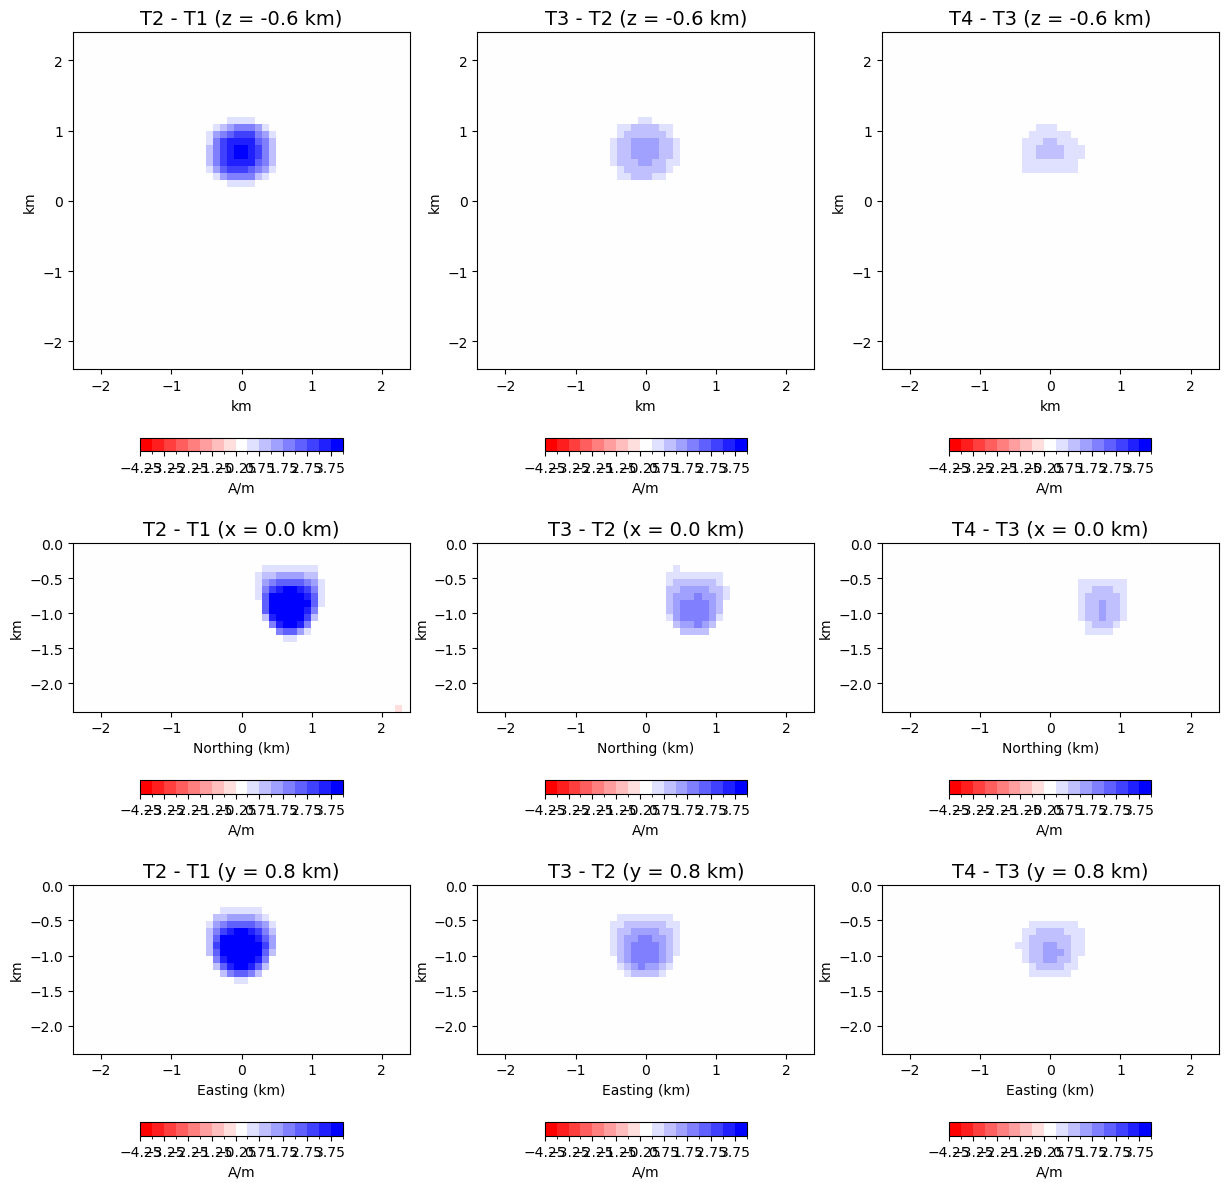

In [32]:
from matplotlib.colors import BoundaryNorm
bounds = np.arange(-4.25, 4.26, 0.5)
cmap = plt.get_cmap("bwr_r")
norm = BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.8
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas2_all[num_opt_2] - betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas3_all[num_opt_2] - betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (betas4_all[num_opt_2] - betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas2_all[num_opt_2] - betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas3_all[num_opt_2] - betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (betas4_all[num_opt_2] - betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)


ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas2_all[num_opt_2] - betas1_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas3_all[num_opt_2] - betas2_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (betas4_all[num_opt_2] - betas3_all[num_opt_2]).reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = cmap, norm = norm,
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

### Step.3

In [33]:
# hyper-parameters
lams_s = np.power(10., np.arange(0.5, 2.6, 0.25))
print("lams_s = {}".format(lams_s))

lams_s = [  3.16227766   5.62341325  10.          17.7827941   31.6227766
  56.23413252 100.         177.827941   316.22776602]


In [ ]:
%%time
params_all = []
betas1_all = []
betas2_all = []
betas3_all = []
betas4_all = []

for lis in range(len(lams_s)):

    params_all.append([lams_s[lis], lams_t[num_opt_2]])
    print("lm1 = {}, lm2 = {}".format(lams_s[lis], lams_t[num_opt_2]))

    model = ADMMGroupLasso(lambda_s = lams_s[lis], 
                           lambda_t = lams_t[num_opt_2], 
                           alpha = alpha, 
                           rho = rho, 
                           eta = eta, 
                           tol = 1e-3)
    model.fit(fobs, 
              Z, 
              D, 
              sw, 
              inv1, 
              inv2, 
              times = 4, 
              num_of_cells = nx*ny*nz
             )
    
    beta_sim1 = model.beta_[0*nx*ny*nz:1*nx*ny*nz] / w1
    beta_sim2 = model.beta_[1*nx*ny*nz:2*nx*ny*nz] / w2
    beta_sim3 = model.beta_[2*nx*ny*nz:3*nx*ny*nz] / w3
    beta_sim4 = model.beta_[3*nx*ny*nz:4*nx*ny*nz] / w4

    betas1_all.append(beta_sim1)
    betas2_all.append(beta_sim2)
    betas3_all.append(beta_sim3)
    betas4_all.append(beta_sim4)

# ndarry
params_all = np.array(params_all)
betas1_all = np.array(betas1_all)
betas2_all = np.array(betas2_all)
betas3_all = np.array(betas3_all)
betas4_all = np.array(betas4_all)

lm1 = 3.1622776601683795, lm2 = 17.78279410038923
iter = 0, delta_s = 0.5543154612736042, delta_t = 0.12231027006474432, delta = 0.5543154612736042
iter = 4000, delta_s = 0.00010023382604394558, delta_t = 0.0035025802400244434, delta = 0.0035025802400244434
iter = 5000, delta_s = 9.39294488597356e-05, delta_t = 0.003184878677149802, delta = 0.003184878677149802
iter = 6000, delta_s = 0.0001111306710958214, delta_t = 0.0028714442660476916, delta = 0.0028714442660476916
iter = 7000, delta_s = 0.00012128569573780283, delta_t = 0.00261435755727026, delta = 0.00261435755727026
iter = 8000, delta_s = 7.81808165691093e-05, delta_t = 0.0023489488057467324, delta = 0.0023489488057467324
iter = 9000, delta_s = 6.369094139722799e-05, delta_t = 0.0021628974362281044, delta = 0.0021628974362281044
iter = 10000, delta_s = 5.304087801645401e-05, delta_t = 0.002013208076398254, delta = 0.002013208076398254
iter = 11000, delta_s = 4.648550359867846e-05, delta_t = 0.00188726981336664, delta = 0.00188726

In [ ]:
import pickle
with open('1007_Params_model_E_new_4d-3.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1007_Betas1_model_E_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas1_all, f)
with open('1007_Betas2_model_E_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas2_all, f)
with open('1007_Betas3_model_E_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas3_all, f)
with open('1007_Betas4_model_E_new_4d-3.pickle', 'wb') as f:
    pickle.dump(betas4_all, f)

In [ ]:
# L-curve
rss2_3 = []
nrm2_3 = []

for lis in range(len(lams_s)):
    
    betas_temp = np.r_[betas1_all[lis]*w1, betas2_all[lis]*w2, betas3_all[lis]*w3, betas4_all[lis]*w4]
    rss_temp = misfit(fobs, Z, betas_temp)
    pen_temp = pen1(betas_temp, alpha = alpha)
    
    rss2_3.append(rss_temp)
    nrm2_3.append(pen_temp)

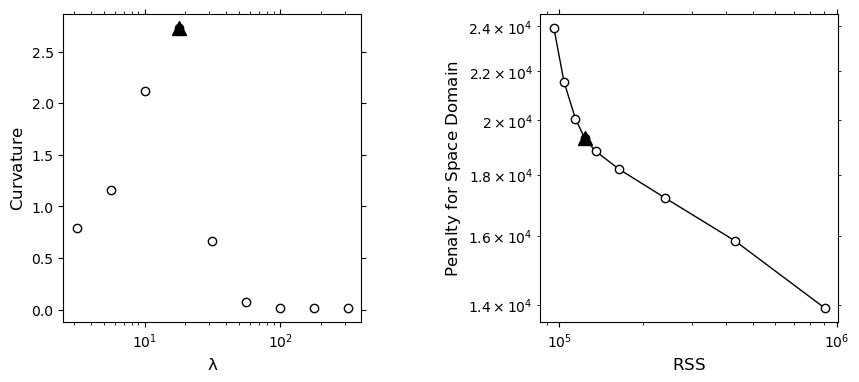

In [39]:
# curvature
fig = plt.figure(figsize = (10, 4))

ax = fig.add_subplot(121)
ax.semilogx(lams_s, calcCurvature2(np.log(rss2_3), np.log(nrm2_3)), "o", ms=6, color='#000000',markerfacecolor='#ffffff', linewidth = 1)

num_opt_3 = np.argmax(calcCurvature2(np.log(rss2_3), np.log(nrm2_3)))

ax.semilogx(lams_s[num_opt_3], calcCurvature2(np.log(rss2_3), np.log(nrm2_3))[num_opt_3], '^', ms=10, color = "black")
ax.set_xlabel(r'${\rm \lambda}$', fontsize = 12)
ax.set_ylabel(r'${\rm Curvature}$', fontsize = 12)

ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

#ax.set_xticks([0, 1e5, 2e5, 3e5])
#ax.ticklabel_format(style="sci",  axis="x",scilimits=(0,0))
ax.ticklabel_format(style="sci",  axis="y", scilimits=(0,0))

#ax.set_xlim(2e-2, 5e2)
#ax.set_ylim(-0.5, 6.5)

ax = fig.add_subplot(122)
ax.loglog(rss2_3, nrm2_3, 'o-', ms=6, color='#000000', markerfacecolor='#ffffff', linewidth = 1)
ax.loglog(rss2_3[num_opt_3], nrm2_3[num_opt_3], '^', ms=10, color = "black")
ax.set_xlabel(r'$\text{RSS}$', fontsize = 12)
ax.set_ylabel(r'$\text{Penalty for Space Domain}$', fontsize = 12)
#ax.set_xlim(1e3, 13e4)
#ax.set_ylim(2e3, 3e4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')

plt.subplots_adjust(wspace=0.6)

In [40]:
print("optimal lambda_s = {}".format(lams_s[num_opt_3]))

optimal lambda_s = 17.78279410038923
